# Component A, Question 4: System Integration and Evaluation

This notebook evaluates the **closed-loop autonomous navigation** run in Webots
(`webots/worlds/component_a_navigation.wbt`, controller
`navigation_controller`). The system chains all three earlier stages:

| Stage | Input → output | Where |
|---|---|---|
| Perception (Q1) | LiDAR + camera logs → fused semantic occupancy grid | `question1/outputs/fused_map.npz` |
| Planning (Q2) | fused grid → A\* path → 4 waypoints | `question2/outputs/planned_path.json` |
| Control (Q3) | waypoints + pose → heading PID → wheel speeds | `navigation_controller.py` |
| Safety (live perception) | LiDAR front sector each step → emergency stop if < 5.5 cm | `navigation_controller.py` |

The controller reads the robot pose every 16 ms, computes the heading error to
the active waypoint, and sets the wheel speeds through the PID controller. That
is the closed loop. Three PID gain settings were run on the same route, with the
supervisor returning the robot to the start between trials.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

NAV_DIR = Path("../../webots/data/navigation")
GT_FILE = Path("../../webots/data/ground_truth.json")
MAP_FILE = Path("../question1/outputs/fused_map.npz")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

ROBOT_RADIUS = 0.037
summary = json.load(open(NAV_DIR / "summary.json"))
truth = json.load(open(GT_FILE))
plan = summary["plan"]
waypoints = np.array(plan["waypoints"])
trial_info = {t["name"]: t for t in summary["trials"]}
trials = {name: pd.read_csv(NAV_DIR / f"trial_{name}.csv",
                            na_values=["inf"])
          for name in trial_info}
LABELS = {name: f"{name}: Kp={t['kp']}, Ki={t['ki']}, Kd={t['kd']}"
          for name, t in trial_info.items()}
COLOURS = {"low_kp": "tab:blue", "tuned": "tab:orange", "high_kp": "tab:green"}

fmap = np.load(MAP_FILE)
extent = (float(fmap["x_min"]),
          float(fmap["x_min"]) + fmap["fused"].shape[1] * float(fmap["resolution"]),
          float(fmap["y_min"]),
          float(fmap["y_min"]) + fmap["fused"].shape[0] * float(fmap["resolution"]))
fused_cmap = ListedColormap(["#bdbdbd", "white", "black",
                             "red", "limegreen", "blue"])
print("Waypoints:", plan["waypoints"])

Waypoints: [[-0.6, -0.6], [-0.39, 0.45], [-0.33, 0.51], [0.39, 0.61], [0.6, 0.6]]


In [2]:
def cross_track_error(px, py):
    """Shortest distance from a point to the planned waypoint polyline."""
    best = np.inf
    for a, b in zip(waypoints[:-1], waypoints[1:]):
        d = b - a
        t = np.clip(((px - a[0]) * d[0] + (py - a[1]) * d[1]) / (d @ d), 0, 1)
        best = min(best, math.hypot(px - a[0] - t * d[0], py - a[1] - t * d[1]))
    return best


def body_clearance(x, y):
    """Gap between the robot's body and the nearest true obstacle,
    landmark or wall (negative would mean a collision)."""
    gaps = [0.75 - abs(x), 0.75 - abs(y)]
    for o in truth["obstacles"]:
        dx = max(abs(x - o["x"]) - o["size_x"] / 2, 0)
        dy = max(abs(y - o["y"]) - o["size_y"] / 2, 0)
        gaps.append(math.hypot(dx, dy))
    for lm in truth["landmarks"]:
        gaps.append(math.hypot(x - lm["x"], y - lm["y"]) - lm["radius"])
    return min(gaps) - ROBOT_RADIUS


for d in trials.values():
    d["cte"] = [cross_track_error(x, y) for x, y in zip(d.x, d.y)]
    d["clearance"] = [body_clearance(x, y) for x, y in zip(d.x, d.y)]

## 1. Planned vs actual trajectory

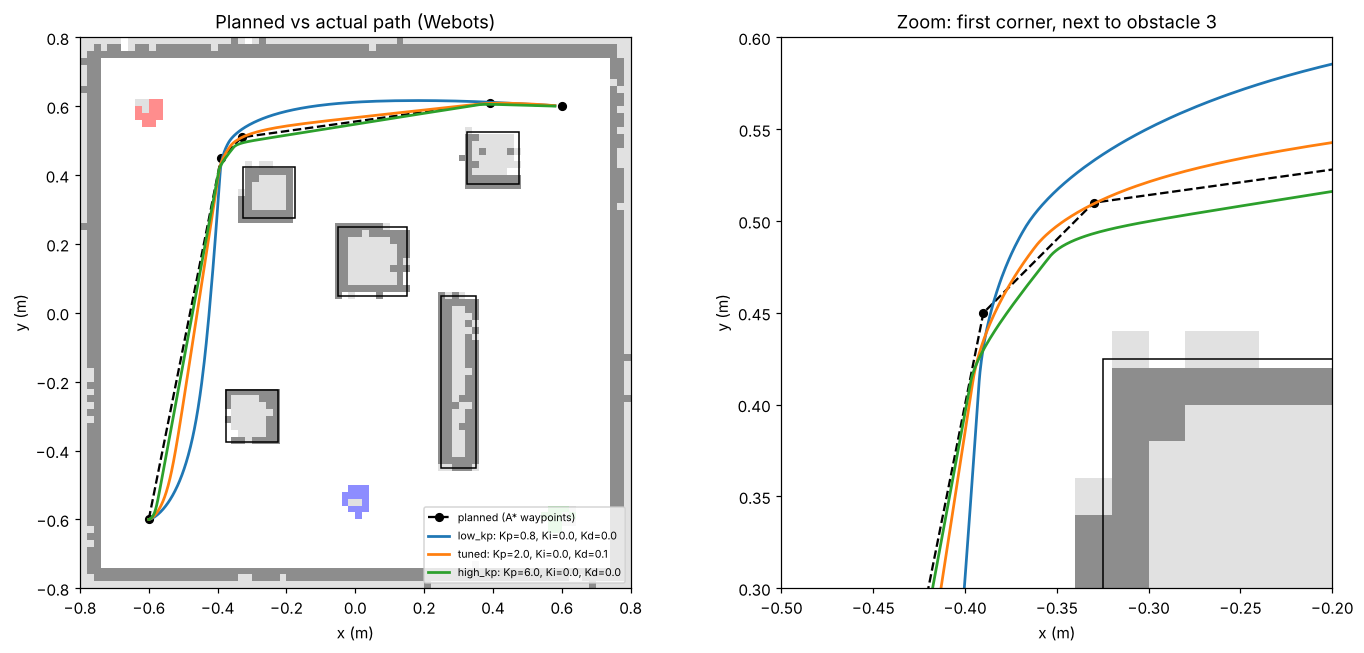

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax in axes:
    ax.imshow(fmap["fused"], origin="lower", extent=extent, cmap=fused_cmap,
              vmin=-1, vmax=4, interpolation="nearest", alpha=0.45)
    for o in truth["obstacles"]:
        ax.add_patch(Rectangle((o["x"] - o["size_x"] / 2,
                                o["y"] - o["size_y"] / 2),
                               o["size_x"], o["size_y"], fill=False,
                               ec="k", lw=1))
    ax.plot(waypoints[:, 0], waypoints[:, 1], "k--o", lw=1.5, ms=5,
            label="planned (A* waypoints)")
    for name, d in trials.items():
        ax.plot(d.x, d.y, lw=1.8, color=COLOURS[name], label=LABELS[name])
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
axes[0].set_xlim(-0.8, 0.8)
axes[0].set_ylim(-0.8, 0.8)
axes[0].set_title("Planned vs actual path (Webots)")
axes[0].legend(fontsize=7, loc="lower right")
axes[1].set_xlim(-0.5, -0.2)
axes[1].set_ylim(0.3, 0.6)
axes[1].set_title("Zoom: first corner, next to obstacle 3")
plt.tight_layout()
plt.savefig(OUT_DIR / "q4_trajectories.png", bbox_inches="tight")
plt.show()

## 2. Tracking errors over time

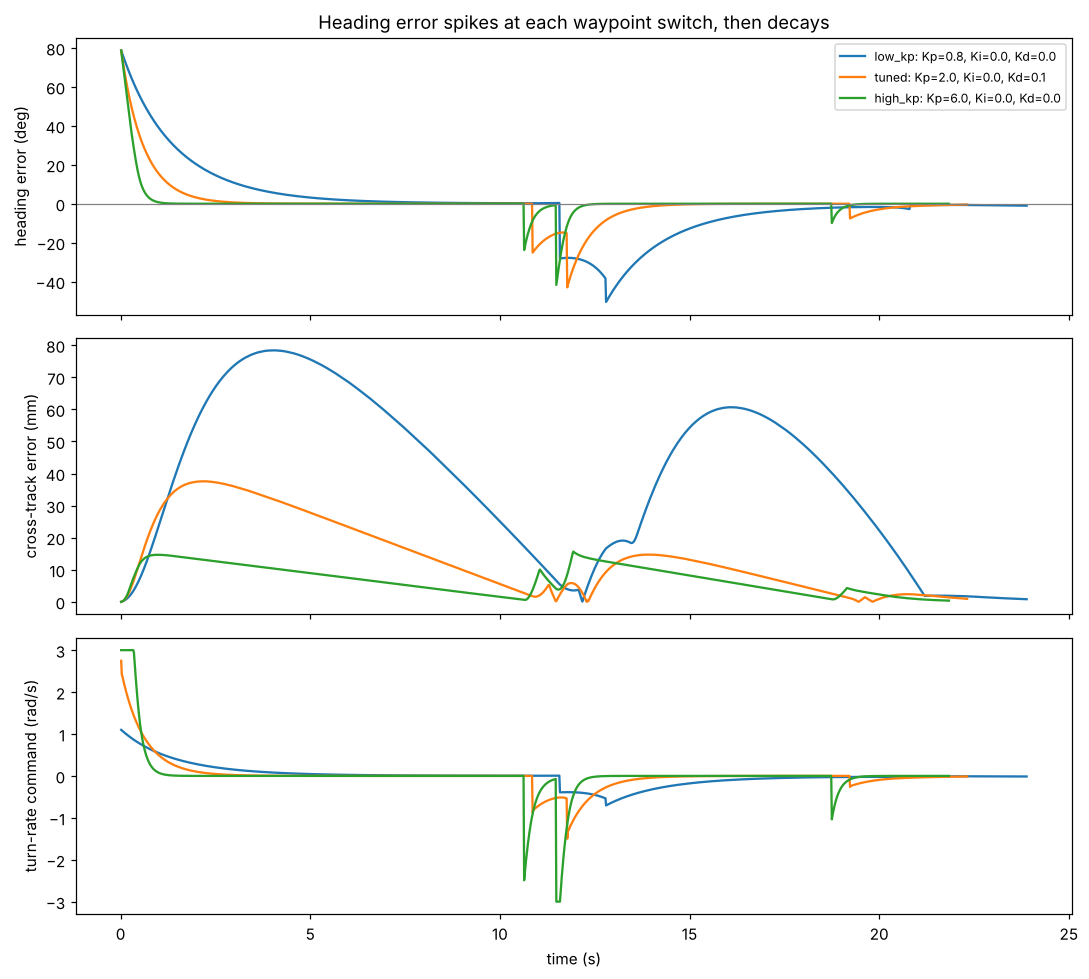

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for name, d in trials.items():
    axes[0].plot(d.t, np.degrees(d.heading_error), color=COLOURS[name],
                 label=LABELS[name])
    axes[1].plot(d.t, 1000 * d.cte, color=COLOURS[name])
    axes[2].plot(d.t, d.omega, color=COLOURS[name])
axes[0].set_ylabel("heading error (deg)")
axes[0].axhline(0, c="grey", lw=0.8)
axes[0].legend(fontsize=8)
axes[1].set_ylabel("cross-track error (mm)")
axes[2].set_ylabel("turn-rate command (rad/s)")
axes[2].set_xlabel("time (s)")
axes[0].set_title("Heading error spikes at each waypoint switch, then decays")
plt.tight_layout()
plt.savefig(OUT_DIR / "q4_errors.png", bbox_inches="tight")
plt.show()

## 3. Performance evaluation

- **Cross-track error (CTE):** distance from the robot to the planned route.
- **Body clearance:** gap between the robot's body and the nearest real obstacle. Negative would mean a collision.
- **Control effort:** total change in the turn-rate command; higher means more actuator activity.
- **Odometry drift:** how far wheel-encoder dead reckoning had drifted from the true position by the end of the run.

In [5]:
rows = []
for name, d in trials.items():
    t = trial_info[name]
    actual_length = np.hypot(np.diff(d.x), np.diff(d.y)).sum()
    rows.append({
        "Gains": LABELS[name].split(": ")[1],
        "Reached goal": t["reached_goal"],
        "Time to goal (s)": t["time_to_goal_s"],
        "Planned length (m)": plan["waypoint_path_length_m"],
        "Actual length (m)": round(actual_length, 3),
        "RMS CTE (mm)": round(1000 * np.sqrt(np.mean(d.cte ** 2)), 1),
        "Max CTE (mm)": round(1000 * d.cte.max(), 1),
        "Final error (mm)": round(1000 * t["final_error_m"], 1),  # stop tolerance 20 mm
        "Min body clearance (mm)": round(1000 * d.clearance.min(), 1),
        "Control effort": round(np.abs(np.diff(d.omega)).sum(), 2),
        "Odometry drift (mm)": round(1000 * t["odometry_drift_m"], 1),
        "Emergency stops": t["emergency_stop_steps"],
    })
performance = pd.DataFrame(rows, index=list(trials)).T
performance.to_csv(OUT_DIR / "q4_performance.csv")
performance

,low_kp,tuned,high_kp
Gains,"Kp=0.8, Ki=0.0, Kd=0.0","Kp=2.0, Ki=0.0, Kd=0.1","Kp=6.0, Ki=0.0, Kd=0.0"
Reached goal,True,True,True
Time to goal (s),23.904,22.336,21.856
Planned length (m),2.0928,2.0928,2.0928
Actual length (m),2.123,2.083,2.065
RMS CTE (mm),45.5,18.0,8.1
Max CTE (mm),78.4,37.6,15.7
Final error (mm),19.9,19.8,19.8
Min body clearance (mm),28.1,26.8,19.9
Control effort,2.55,6.98,15.91


## 4. Odometry vs true position

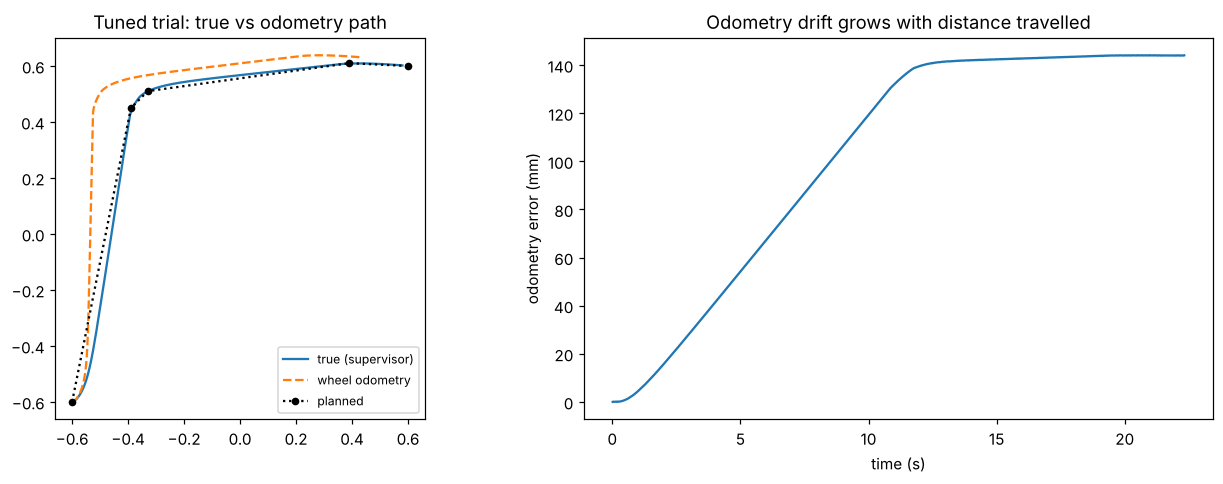

Drift at goal: 144 mm after 2.08 m (6.9% of distance travelled)


In [6]:
d = trials["tuned"]
drift = np.hypot(d.odom_x - d.x, d.odom_y - d.y)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(d.x, d.y, label="true (supervisor)")
axes[0].plot(d.odom_x, d.odom_y, "--", label="wheel odometry")
axes[0].plot(waypoints[:, 0], waypoints[:, 1], "k:o", ms=4, label="planned")
axes[0].set_aspect("equal")
axes[0].legend(fontsize=8)
axes[0].set_title("Tuned trial: true vs odometry path")
axes[1].plot(d.t, 1000 * drift)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("odometry error (mm)")
axes[1].set_title("Odometry drift grows with distance travelled")
plt.tight_layout()
plt.savefig(OUT_DIR / "q4_odometry.png", bbox_inches="tight")
plt.show()
print(f"Drift at goal: {1000 * drift.iloc[-1]:.0f} mm after "
      f"{np.hypot(np.diff(d.x), np.diff(d.y)).sum():.2f} m "
      f"({drift.iloc[-1] / np.hypot(np.diff(d.x), np.diff(d.y)).sum():.1%} "
      f"of distance travelled)")

## 5. Trade-offs between perception, planning and control

**Control responsiveness.** Raising Kp made the robot correct its heading
faster after each waypoint switch. It cut corners less, so cross-track error
fell sharply and the goal was reached slightly sooner. No overshoot or
oscillation appeared even at Kp = 6. The heading loop behaves like an
integrator with a turn-rate limit, and the simulation has no sensor noise or
actuator delay. On a physical robot, high gains would amplify noise in the
heading estimate into constant small corrections, visible here as higher
control effort. That causes wheel chatter and wear, so a moderate gain is the
safer choice for hardware even though the highest gain wins in simulation.

**Planning optimality vs safety margin.** The most accurate controller had
the *smallest* body clearance. It followed the plan faithfully, and the plan
itself passes close to obstacle 3's corner, because an optimal planner hugs
obstacles by design. The low-Kp controller cut the corner on the *outside*
and stayed slightly further away, by luck rather than design. Clearance is
therefore set by the **planner's inflation margin**, not by the controller.
Shortest paths and safe paths pull in opposite directions, and a larger
margin, or a cost term that penalises proximity, buys safety at the price of
path length.

**Perception accuracy.** Mapping errors propagate straight into the plan. The
landmark estimates in Question 1 were within about 1 cm, and the inflation margin
(robot radius + 1 cm, rounded up to whole cells) absorbs errors of that size.
Localisation matters even more. With ideal supervisor pose, the robot's body stayed about 2 cm or more from
every obstacle, but wheel odometry drifted by 10–15 cm (about 7% of the
distance travelled). A robot relying on odometry alone would have believed it was
on the path while actually being off by more than its clearance margin, and
would likely have collided. Accurate perception for *localisation*, not only for
mapping, is therefore the most important link in the chain.

## 6. Practical and ethical implications of deployment in shared human spaces

- **Safety margins are a value judgement.** The 1 cm extra margin used here suits static boxes. Around people, margins must account for human movement and unpredictability, which means larger clearances, lower speeds, and speed limits that depend on distance to people. Standards for mobile robots near people (e.g. ISO 3691-4 for industrial vehicles) exist for this reason.
- **The map is a snapshot.** This system plans once on a static map and only stops for obstacles directly ahead. A person stepping in from the side, a child, or a pet would not be detected in time. Deployment would need continuous detection of people around the whole robot, and replanning.
- **Perception failures are not neutral.** The colour-threshold detector worked because the test world was designed for it. In real spaces, sensors and detectors perform worse in some conditions: poor lighting, dark clothing, reflective surfaces, wheelchairs or mobility aids missing from training data. Errors can therefore fall unevenly on particular groups of people, and testing must deliberately include those cases.
- **Transparency and accountability.** People sharing a space with a robot should be able to predict its movement, for example through signalled intent or consistent behaviour. When something goes wrong, it must be possible to reconstruct why. The logs saved here (pose, target, errors, commands) are a small example of the audit trail a deployed system needs.
- **Fail-safe behaviour.** The emergency stop never triggered in these runs, but its threshold sits right at the LiDAR's minimum range, so a closer object would be invisible. Real systems need redundant sensing and a defined safe state (stop) whenever localisation or perception confidence drops.